# PROJETO DE CHURN
**Descrição:** No contexto de negócios o termo "churn" é utilizado para descrever quantos clientes cancelaram, ou pararam de utilizar, seus serviços. Esse valor se converte diretamente em uma perda de receita para a empresa e, portanto, é interessante criar estratégias para diminuir o churn. Neste projeto será analisado um conjunto de dados de clientes de um banco com indicação se eles fecharam suas contas ou não.   

**Objetivos:** Fazer um estudo comparativo de diferentes modelos de Machine Learning (ML) para fazer uma previsão se um cliente irá cancelar sua conta ou não baseado nas informações disponíveis.

**Disponível em:** [Churn Modelling](https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling/data)

**Descrição dos dados:**
| Variável | Descrição |
| :------: | :-------: |
| Customer ID | Número de identificação único do cliente |
| Surname | Sobrenome do cliente |
| CreditScore | Pontuação de crédito do cliente |
| Geography | País de origem do cliente |
| Gender | Gênero do cliente |
| Age | Idade do cliente |
| Tenure | Número de anos que o cliente utiliza os serviços do banco |
| Balance | Saldo total da conta do cliente |
| NumOfProducts | Número de produtos do banco que o cliente utiliza |
| HasCrCard | Indicador binário se o cliente tem cartão de crédito no banco ou não |
| IsActiveMember | Indicador binário se o cliente é um membro ativo do banco ou não |
| EstimatedSalary | Salário estimado do cliente |
| Exited | Indicador binário se o cliente terminou sua conta ou não |

**Nota importante:** O conjunto de dados analisados já está previamente limpo, por esse motivo não foi necessária uma etapa de limpeza dos dados.

In [555]:
# Bibliotecas gerais
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from pathlib import Path

# Processamento dos dados e análise dos resultados 
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve, make_scorer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from skopt import BayesSearchCV
from skopt.space import Categorical, Real, Integer

# Modelos de ML 
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

import warnings

warnings.filterwarnings("ignore")

pd.options.display.float_format = "{:20.2f}".format
pd.set_option("display.max_columns", 999)

## 1. Análise Exploratória

**Objetivos:** Fazer uma avaliação inicial de cada variável disponível e como elas se relacionam com a variável de interesse.

Para começar, carregamos os dados da base em um dataframe e fazemos uma análise inicial da estrutura

In [556]:
df = pd.read_csv(Path("data") / "Churn_Modelling.csv", index_col=0)
df.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,,,,,,,,,,,,,
1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [557]:
df.shape

(10000, 13)

In [558]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 1 to 10000
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  str    
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  str    
 4   Gender           10000 non-null  str    
 5   Age              10000 non-null  int64  
 6   Tenure           10000 non-null  int64  
 7   Balance          10000 non-null  float64
 8   NumOfProducts    10000 non-null  int64  
 9   HasCrCard        10000 non-null  int64  
 10  IsActiveMember   10000 non-null  int64  
 11  EstimatedSalary  10000 non-null  float64
 12  Exited           10000 non-null  int64  
dtypes: float64(2), int64(8), str(3)
memory usage: 1.2 MB


In [559]:
df["CustomerId"] = df["CustomerId"].astype("str")
df.describe(include=["str"])

,CustomerId,Surname,Geography,Gender
count,10000,10000,10000,10000
unique,10000,2932,3,2
top,15634602,Smith,France,Male
freq,1,32,5014,5457


In [560]:
df.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,650.53,38.92,5.01,76485.89,1.53,0.71,0.52,100090.24,0.20
std,96.65,10.49,2.89,62397.41,0.58,0.46,0.50,57510.49,0.40
min,350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.00
25%,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51002.11,0.00
50%,652.00,37.00,5.00,97198.54,1.00,1.00,1.00,100193.91,0.00
75%,718.00,44.00,7.00,127644.24,2.00,1.00,1.00,149388.25,0.00
max,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.00


Como foi comentado anteriormente, o conjunto de dados foi disponibilizado limpo, assim, a análise inicial não apresenta valores discrepantes da realidade e podemos seguir diretamente para a análise descritiva (EDA) das variáveis de interesse. 

A variável "*CustomerId*" é identificadora individual de cada cliente, já a variável "*surname*" representa o sobrenome do cliente e não tem poder preditivo, portanto não serão analisados ou utilizados para os modelos de ML.

Podemos perceber também que há um número grande de clientes sem saldo em conta, pelo menos 25% da base. Podemos criar uma nova variável para analisar esses diferentes grupos também, "*HasBalance*".

In [561]:
df["HasBalance"] = df["Balance"] != 0
df.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,HasBalance
RowNumber,,,,,,,,,,,,,,
1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,False
2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,True
3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,True
4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,False
5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,True


A variável "*Exited*" é indicadora se o cliente cancelou o serviço contratado ou não, portanto é necessário fazer uma avaliação inicial de sua distribuição no conjunto.

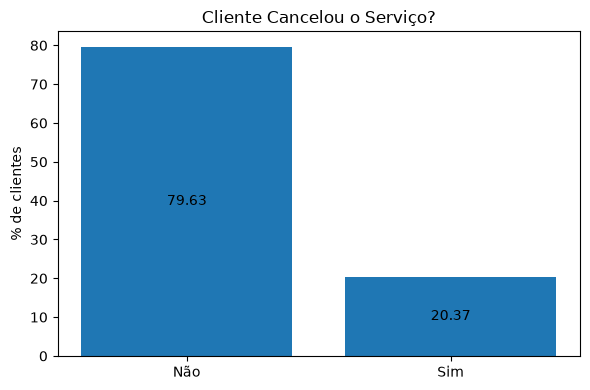

In [562]:
fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot()

labels = df["Exited"].value_counts().index.astype(str).map({"0": "Não", "1": "Sim"})
total_percent = df["Exited"].value_counts() / len(df["Exited"]) * 100

res = ax.bar(labels, total_percent)
ax.bar_label(res, label_type="center")
ax.set_title("Cliente Cancelou o Serviço?")
ax.set_ylabel("% de clientes")

plt.tight_layout()
plt.show()

Na base analisada, a distribuição entre as categorias de clientes que cancelaram os serviços (20,4 %) e clientes que permaneceram com o banco (79,6 %) é desbalanceada, será necessário levar isso em conta para montar os modelos de ML.

Para analisar as variáveis de interesse serão utilizadas as funções "resumir_categóricas", "distribuicao" e comparar, implementadas abaixo

In [563]:
def resumir_categoricas(features, target, df):
    """
    Cria uma figura para resumir as variáveis categóricas no conjunto.
    Gráficos de contagem total de cada grupo a esquerda e de porcentagem do grupo que cancelou os serviços a direita 
    """
    fig, ax = plt.subplots(nrows=len(features), ncols=2, squeeze=False, figsize=(12, len(features) * 5.5))

    for idx, feature in enumerate(features):
        resumo = (df.groupby(feature, dropna=False, observed=True)[target]
                    .agg(total="size", churn="sum")
                    .sort_values("total", ascending=False)
        )

        resumo["taxa"] = 100 * resumo["churn"] / resumo["total"]

        labels = [
            str(valor) for valor in resumo.index
        ]

        # Gráfico 1: quantidade de clientes por categoria
        barras_total = ax[idx, 0].bar(labels, resumo["total"], color="steelblue")

        ax[idx, 0].bar_label(barras_total, fmt="%.0f", padding=3)

        ax[idx, 0].set_xlabel("Número de clientes")
        ax[idx, 0].set_title(f"Distribuição de clientes — {feature}")

        # Gráfico 2: taxa de churn dentro de cada categoria
        barras_churn = ax[idx, 1].bar(labels, resumo["taxa"], color="darkorange", label="Clientes com churn")

        ax[idx, 1].bar_label(barras_churn, labels=[f"{taxa:.1f}%" for taxa in resumo["taxa"]], padding=3)

        ax[idx, 1].yaxis.set_major_formatter(PercentFormatter(100))
        ax[idx, 1].set_xlabel("Taxa de churn na categoria")
        ax[idx, 1].set_title(f"Taxa de churn — {feature}")
        ax[idx, 1].set_ylim(0, 110)

    plt.tight_layout()
    plt.show()

In [564]:
def distribuicao(features, df, n_cols=3, bins=20):
    """
    Cria uma figura para resumir a distribuição das variáveis numéricas no conjunto.
    """
    n_rows = int(np.ceil(len(features) / 3))

    fig, ax = plt.subplots(ncols=n_cols, nrows=n_rows, squeeze=False, figsize=(4*n_cols, 4*n_rows))
    for row in range(n_rows):
        for col in range(n_cols):
            idx = n_cols*row + col
            if idx >= len(features):
                ax[row, col].set_visible(False)
                continue

            feature = features[idx]
            ax[row][col].hist(df[feature], bins=bins)
            ax[row][col].set_title(feature)
            ax[row][col].set_xlabel(feature)
            ax[row][col].set_ylabel("Ocorrência")

    plt.tight_layout()
    plt.show()

In [565]:
def comparar(features, target, df, n_cols=3):
    """
    Cria uma figura para comparar a distribuição dos clientes que saíram ou ficaram em relação a cada variável.
    """
    n_rows = int(np.ceil(len(features) / 3))

    fig, ax = plt.subplots(ncols=n_cols, nrows=n_rows, squeeze=False, figsize=(4*n_cols, 4*n_rows))
    for row in range(n_rows):
        for col in range(n_cols):
            idx = n_cols*row + col
            if idx >= len(features):
                ax[row, col].set_visible(False)
                continue

            feature = features[idx]
            sns.boxplot(x=target, y=feature, data=df, ax=ax[row][col])
            ax[row][col].set_title(feature)
            ax[row][col].set_xlabel(target)
            ax[row][col].set_ylabel(feature)

    plt.tight_layout()
    plt.show()

In [566]:
features_numericas = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"]
features_categoricas = ["Gender", "Geography", "HasCrCard", "IsActiveMember", "NumOfProducts", "HasBalance"]

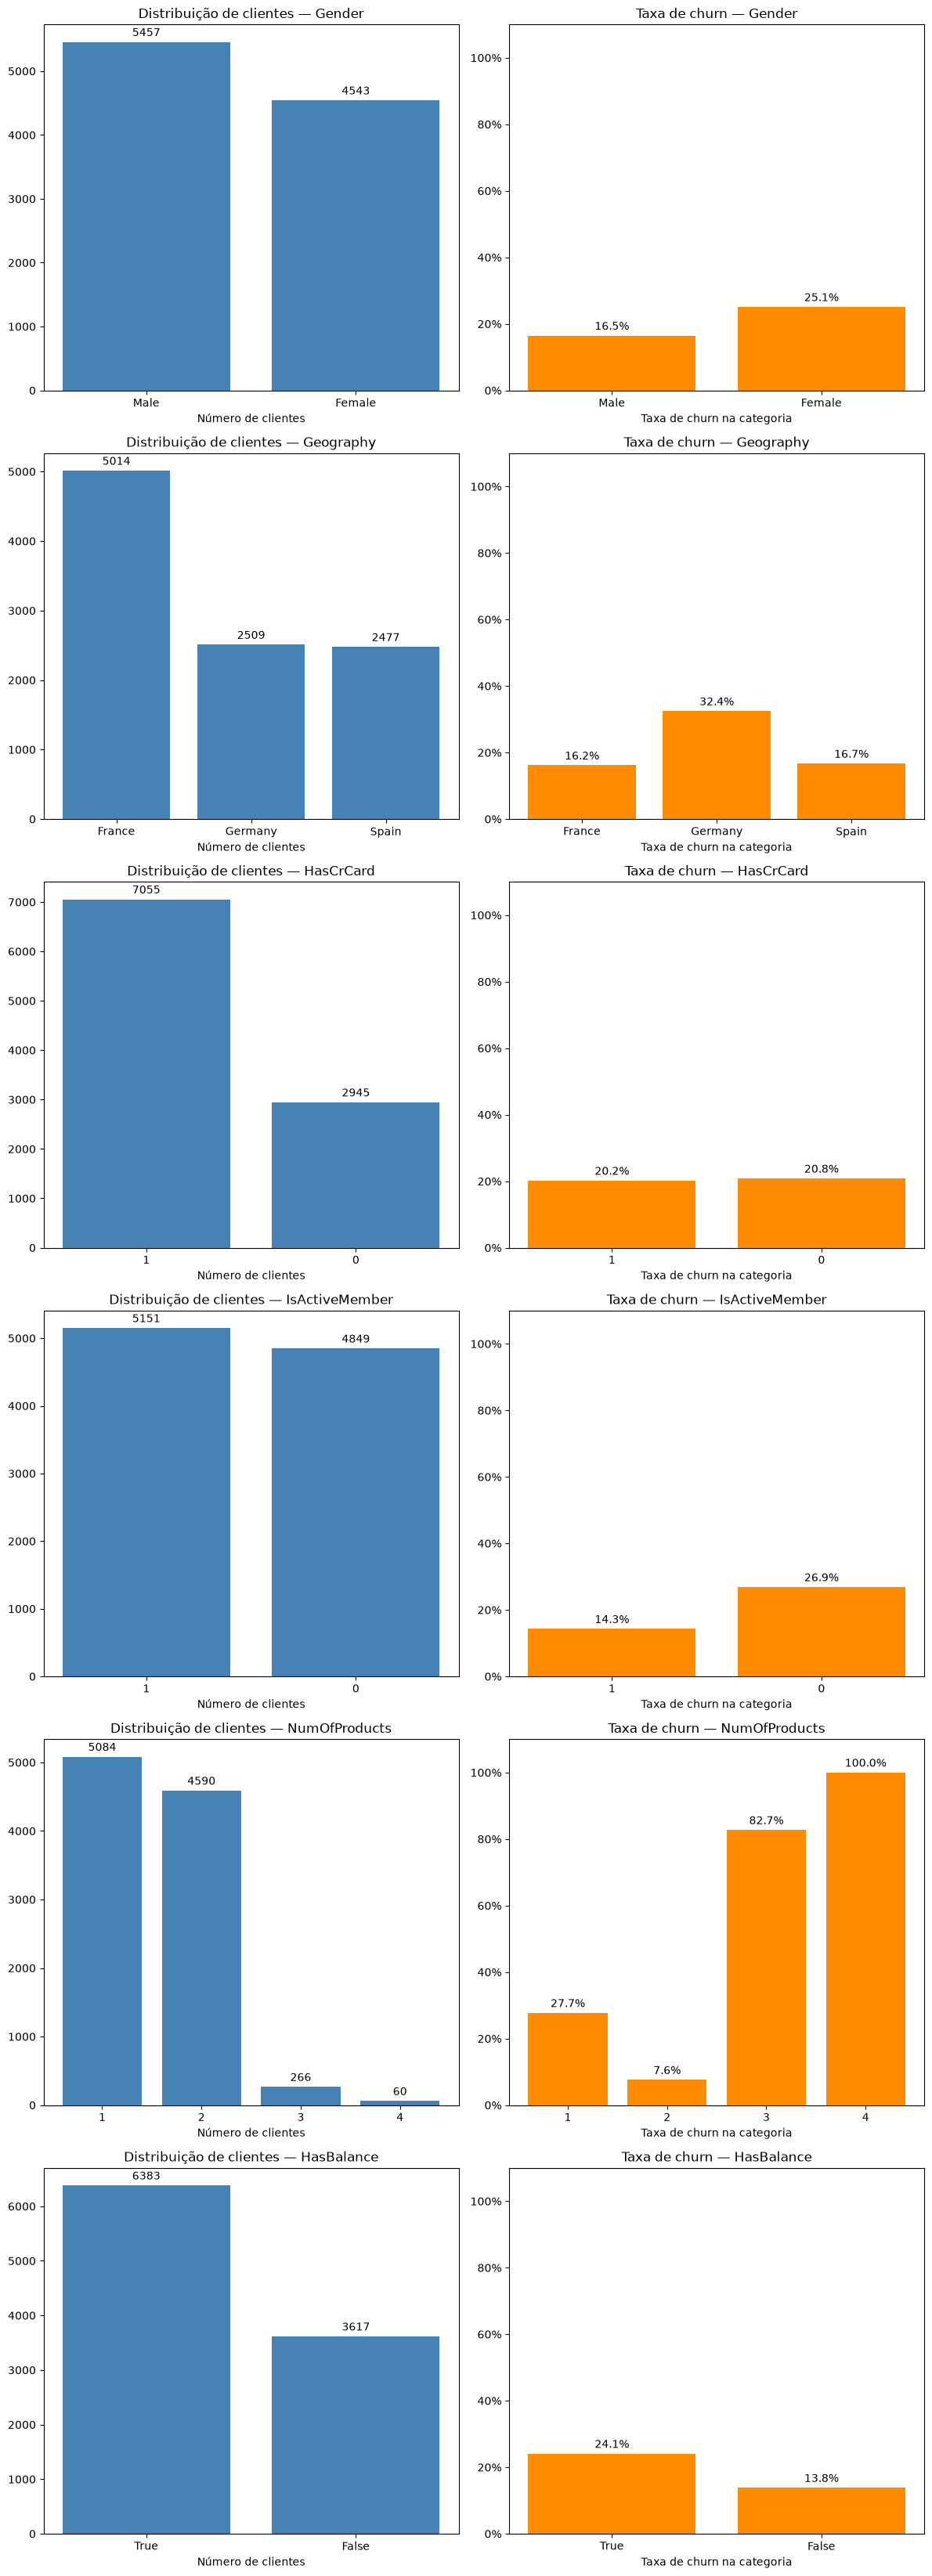

In [567]:
resumir_categoricas(features_categoricas, "Exited", df)

### Análise das variáves categóricas

**Gênero**:

- O número de clientes do sexo masculino e feminino está bem equilibrado, aproximadamente 50 % para cada.
- Apesar de estarem equilibrados, a taxa de cancelamento do público feminino (25,1 %) está proporcionalmente maior que no público masculino (16,5 %).

**Geografia**:
- O número de clientes na França é praticamente o dobro dos clientes tanto na Espanha quanto na Alemanha.
- A taxa de cancelamento na Alemanha (32,4 %) é o dobro que os outros países em que o banco está presente, frança (16,2 %) e Espanha (16,7 %).

**Tem cartão de crédito? (HasCrCard)**:
- É uma distribuição desbalanceada, a maioria (70,6 %) dos clientes do banco possui cartão de crédito
- Em proporção, os dois grupos apresentam taxas de cancelamento próximas entre quem tem cartão de crédito (20,2 %) e quem não tem cartão de crédito (20,8 %)

**É um membro ativo? (IsActiveMember)**:
- Distribuição equilibrada, aproximadamente 50 % dos clientes são ativos e 50 % não são.
- A taxa de cancelamento de clientes que não são ativos (26,9 %) é proporcionalmente maior que a taxa de cancelamento para clientes ativos (14,3 %)

**Número de produtos contratados (NumOfProducts)**
- A maior parte dos clientes (96,7 %) tem até dois produtos contratados. Apenas 3,3 % dos clientes tem 3 ou 4 produtos contratados.
- As taxas de cancelamento entre os clientes com diferentes números de produtos varia consideravelmente entre os grupos.

| Número de produtos | Percentual do total  | Taxa de Cancelamento (Dentro do grupo) |
| :----------------: | :------------------: | :------------------------------------: |
|         1          |         50,8%        |                 27,7%                  |
|         2          |         45,9%        |                  7,5%                  |
|         3          |          2,7%        |                 82,7%                  |
|         4          |          0,6%        |                100,0%                  |

- É interessante notar que clientes com 3 produtos apresentam uma taxa de cancelamento muito alta (82,7%) e a totalidade de clientes com 4 produtos saíram. É interessante propor uma investigação do motivo desse comportamento.

**Cliente tem Saldo em conta? (HasBalance)**
- Distribuição levemente desequilibrada, 63,8 % dos clientes tem saldo em conta e 36,1 % dos  clientes não tem.
- A taxa de cancelamento entre os grupos apresenta uma diferença considerável, 13,8 % para clientes sem saldo e 24,1 % para clientes com saldo. 

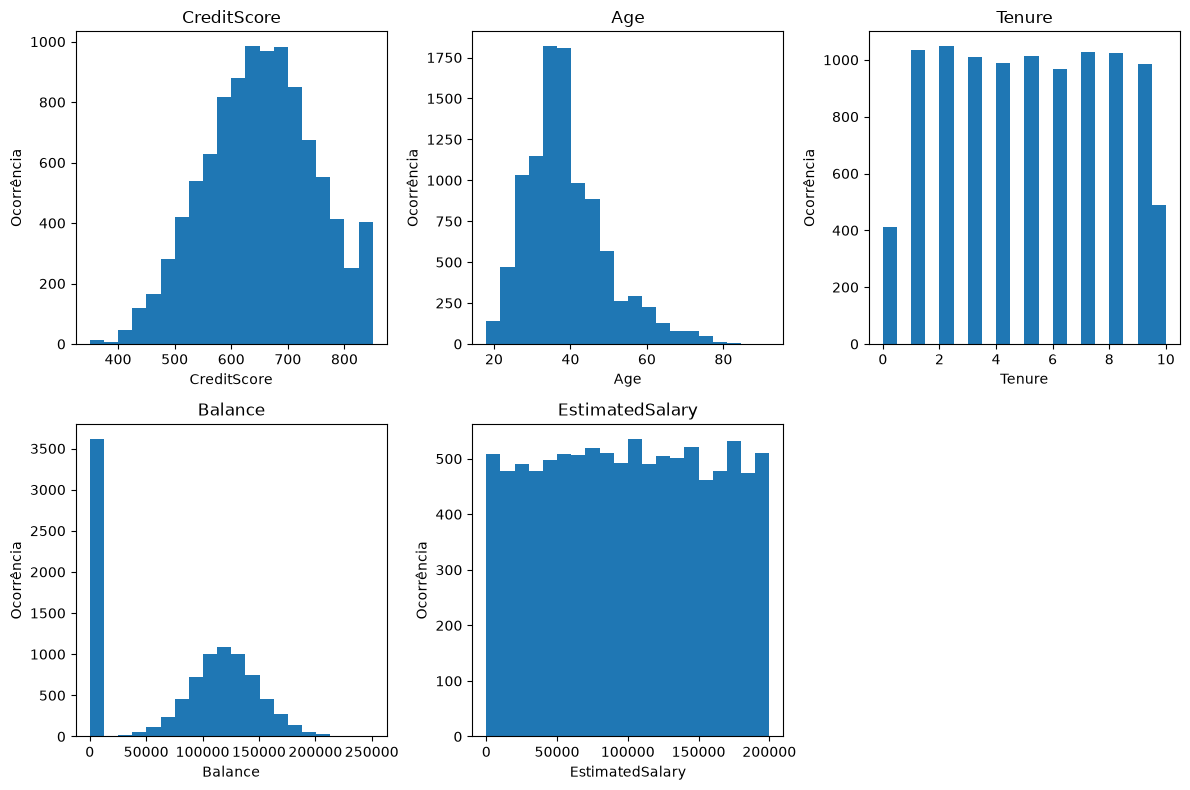

In [568]:
distribuicao(features_numericas, df, n_cols=3)

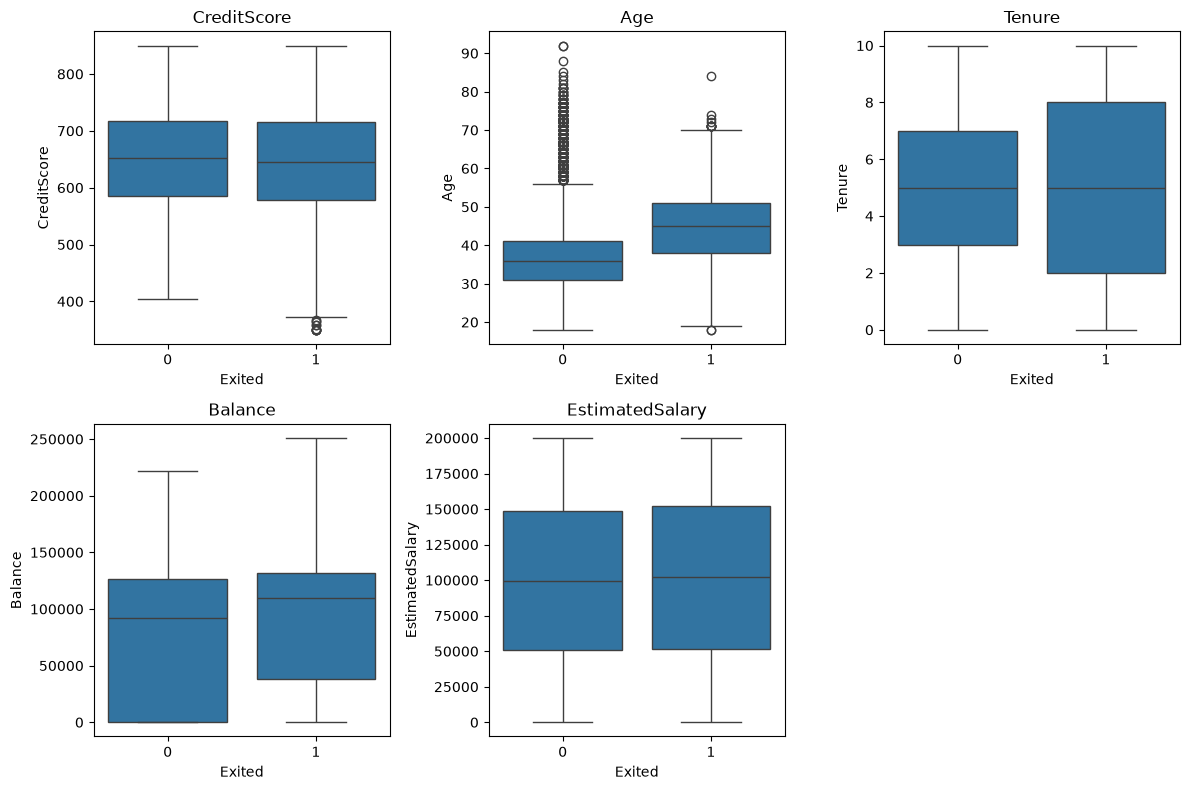

In [569]:
comparar(features_numericas, "Exited", df)

### Análise das variáveis contínuas
Podemos perceber que as variáveis de tempo de contrato (Tenure), pontuação de crédito (CreditScore) e salário estimado (EstimatedSalary) apresentam uma distribuição similar entre os grupos de clientes que permaneceram e que cancelaram os serviços.

Há uma separação mais acentuada entre os grupos na variável idade (Age). O grupo de clientes que cancela o serviço tem uma mediana acima do terceiro quartil do grupo de clientes que permaneceram com o banco, isso indica uma possível correlação entre a faixa etária dos clientes com o resultado. Além disso, a variável de saldo na conta (Balance) também apresenta uma diferença pronunciada na distribuição entre os grupos. Em geral os clientes que cancelam o serviço tem um saldo maior em conta. 

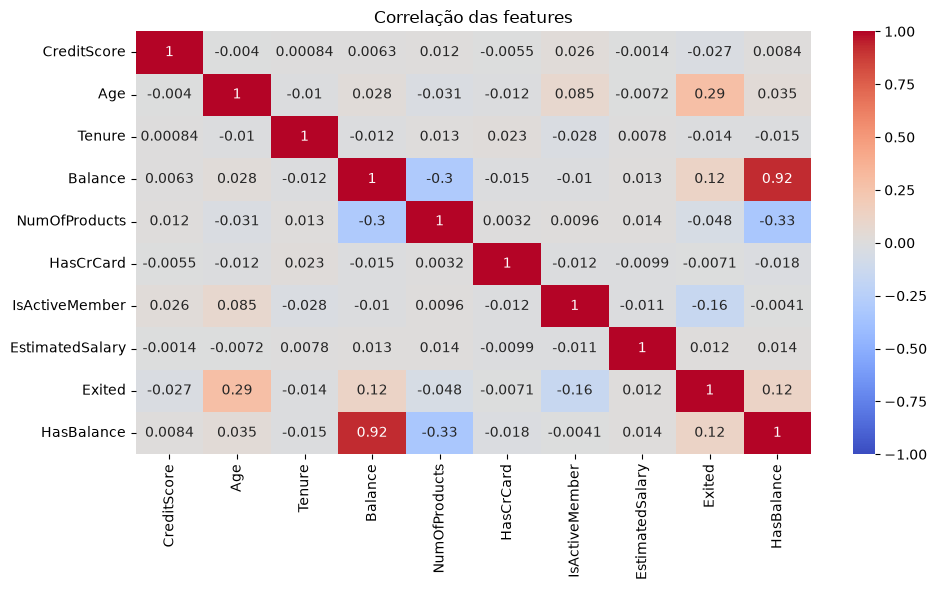

In [570]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot()

norm = mcolors.CenteredNorm()

sns.heatmap(df.corr(numeric_only=True), ax=ax, annot=True, cmap="coolwarm", norm=norm)
ax.set_title("Correlação das features")
plt.tight_layout()
plt.show()

### Análise de correlação das variáveis
A matriz de correlação permite avaliar a interdependência entre as variáveis, valores distantes de 0 apresentam algum tipo de correlação linear entre as variáveis analisadas e o sinal indica se é uma relação direta ou inversa. Uma análise inicial da matriz de correlação traz as seguintes conclusões:
- Há uma predominância de valores próximos de 0 entra as variáveis analisadas, indicando que não há correlação linear entre elas. 
- As variáveis de saldo em conta (Balance) e Número de produtos (NumOfProducts) tem uma correlação negativa, isso indica que clientes com mais produtos contratados tendem a ter um menor saldo em conta.
- Com relação à variável alvo (Exited), percebemos que a variável de idade (Age) e saldo em conta (Balance) apresentam uma correlação positiva, reforçando as conclusões anteriores com base nas análises de distribuição.
- A variável indicativa de atividade do cliente (IsActiveMember) apresenta uma correlação negativa com a variável alvo (Exited), indicando que clientes menos ativos tem maior tendência para cancelar o serviço.

Apesar de não terem sido identificadas correlações diretas entre as outras variáveis e o alvo, não podemos excluir elas da análise pois podem ter uma interdependência não linear ou interações entre variáveis influenciando o resultado.

## 2. Implementação e Comparação de Modelos de Machine Learning
**Objetivos:** 
- Separar o conjunto de dados em subconjuntos de treino e de teste dos modelos de ML que serão implementados.
- Fazer uma comparação entre os diferentes modelos e determinar o melhor modelo para previsão deste conjunto de dados.

### Codificação e rotulação das variáveis categóricas
O primeiro passo para a aplicação dos algoritmos de ML é a codificação e rotulação das variáveis categóricas em representações numéricas. Para isso, vamos utilizar o algoritmo de *one hot encoding*, que cria uma coluna nova indicativa para cada valor da variável nominal, para as variáveis *Geography* e *Gender*

### Preparação dos conjuntos de treinamento e teste
Para montar os modelos de ML vamos separar o conjunto de dados total em subconjuntos de treinamento e de teste da seguinte forma:
- *X_train* e *Y_train* serão utilizados para treinar o modelo e representam 80% dos dados do conjunto total
- *X_test* e *Y_test* serão utilizados para validar o modelo após o treinamento e representam 20% dos dados do conjunto total.

Para garantir que os conjuntos de treino e de teste tenham proporções similares de clientes que saíram e que permaneceram, vamos utilizar a função *train_test_split* com o parâmetro *stratify=Y*.

In [571]:
# Seed para garantir reprodutibilidade
rs = 42

# Separação das colunas com dados numéricos e categóricos
colunas_numericas = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard", 
            "IsActiveMember", "EstimatedSalary", "HasBalance"]

colunas_categoricas = ["Gender", "Geography"]

# Separação dos fatores utilizados e variável target
X = df[colunas_numericas+colunas_categoricas]
Y = df["Exited"]

# Separação do conjunto completo em conjuntos de treino e teste
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=rs, stratify=Y)
Y_train

RowNumber
2152    1
8393    1
5007    0
4118    0
7183    0
       ..
4556    1
4645    0
8943    0
2936    0
6207    0
Name: Exited, Length: 8000, dtype: int64

### Implementação dos modelos de machine learning
Neste projeto vamos comparar os seguintes modelos de ML
- Random Forest;
- Logistic Regression;
- XGBoost.

A avaliação dos modelos será realizada analisando os parâmetros *acurácia*, *precisão*, *recall* e *f1 score*. Essas medidas são relações entre os valores absolutos presentes no conjunto de dados e as previsões feitas pelo modelo que podem ser: VP (verdadeiro positivo), FP (falso positivo), VN (verdadeiro negativo) e FN (falso negativo).
| Métrica | Definição matemática | Descrição |
| :-----: | :------------------: | :-------: |
| *Acurácia* | $\frac{VP + VN}{\text{Total de clientes}}$ | Mede a quantidade total de acertos do modelo em relação ao total de clientes |
| *Precisão* | $\frac{VP}{VP+FP}$ | Mede a quantidade de acertos positivos do modelo em relação ao total de clientes que o modelo previu como positivos |
| *Recall* | $\frac{VP}{\text{Total de clientes positivos}}$ | Mede a quantidade de acertos positivos do modelo em relação ao total de clientes positivos |
| *f1 score* | $2\frac{\text{Precisão}\times\text{Recall}}{\text{Precisão}+\text{Recall}}$ | Média harmônica entre precisão e recall. Representa um equilíbrio entre essas duas métricas |

Em um estudo de churn, as métricas mais importantes são o *recall* e a *precisão*. Em geral, é muito custoso para um negócio perder um cliente, portanto, é comum sacrificar uma acurácia mais alta no modelo por outro que consiga ter precisão e recall melhores no grupo de clientes que cancelaram os serviços.

Idealmente, em um projeto como esse, seria necessário realizar um estudo técnico para avaliar os custos relacionados a não identificar um cliente que irá cancelar o serviço (Falso Negativo) e a identificar um cliente que não irá sair (Falso Positivo). Para simular um projeto real e identificar o custo relacionado com cada modelo, vou propor que perder um cliente representa uma perda de receita de R$ 100,00 por mês e, quando identificamos um cliente como churn, podemos oferecer um desconto de 20%, reduzindo a receita para vinda do cliente para R$ 80,00 por mês. Para simplificar a análise, vamos assumir que todos os clientes que foram identificados como churn vão se manter como clientes.

Nessa situação, o custo total sem modelo pode ser calculado com 100 (Número de clientes que saíram), o custo total com o modelo será 100*(Falso Negativos) + 20(Falsos positivos + Verdadeiros positivos) e a economia total será a diferença entre os dois custos. A economia gerada por um modelo será utilizada como métrica para classificar as melhores configurações para cada um.

Para realizar a otimização dos hiperparâmetros em cada modelo, é necessária a aplicação de um algoritmo de busca. A tabela abaixo apresenta os três algoritmos mais populares, método de funcionamento e pontos positivos e negativos de cada um.
| Método | Funcionamento | Prós | Contras |
| :----: | :-----------: | :--: | :-----: |
| Grid Search (Busca em grade) | Verifica todas as combinações possíveis dos hiperparâmetros do modelo | Garante que vai encontrar a configuração ideal do modelo. | Método muito custoso computacionalmente, demanda muita memória e tempo de execução. |
| Random Search (Busca aleatória) | Verifica diferentes combinações aleatórias dos hiperparâmetros do modelo | Execução Rápida, bom para fazer testes iniciais de um modelo. | Não garante encontrar uma configuração boa de hiperparâmetros do modelo. |
| Bayes Search (Busca Bayesiana) | Utiliza o teorema de Bayes e um modelo estatístico base para buscar no espaço de hiperparâmetros. A cada iteração atualiza o modelo probabilístico para determinar qual a próxima combinação a ser testada. | Tende a conseguir resultados melhores que a busca aleatória e não tem custo computacional tão grande quanto a busca em grade. | Não garante que vai encontrar a melhor configuração possível do modelo. |

Para este projeto, os modelos vão ser otimizados com o Bayes Search, como forma de buscar um equilíbrio entre custo computacional e qualidade do modelo.

In [572]:
def economia_por_cliente(y_true, y_pred, receita_cliente = 100, desconto=0.20):
    """
    Calcula a economia por cliente de um modelo a partir das previsões do modelo
    """
    vn, fp, fn, vp = confusion_matrix(y_true, y_pred).ravel()

    custo_sem_modelo = receita_cliente * (fn + vp)

    valor_desconto = receita_cliente*desconto

    custo_com_modelo = receita_cliente * fn + valor_desconto * (fp + vp)

    economia = custo_sem_modelo - custo_com_modelo

    return economia / len(y_true)

In [573]:
# Rotina de preprocessamento dos dados para criar a pipeline de análise

def criar_pipeline(modelo):
    """
    Cria a pipeline completa de preprocessamento dos dados e implementação do modelo
    """
    preprocessamento = ColumnTransformer([
        ("numericas", StandardScaler(), colunas_numericas),
        ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), colunas_categoricas)
    ])
    
    return Pipeline(
        [
            ("preprocessamento", preprocessamento),
            ("modelo", modelo)
        ]
    )

#### Implementação do modelo Random Forest

In [574]:
# Inicialização da pipeline para o modelo Random Forest
pipe_RF = criar_pipeline(RandomForestClassifier(random_state=rs))

# Espaço de hiperparâmetros a serem analisados
espaco_parametros = {
    'modelo__n_estimators': Integer(50, 1000),
    'modelo__max_depth': Integer(3, 10),
    'modelo__min_samples_split':Integer(2, 20),
    'modelo__min_samples_leaf':Integer(1, 20),
    'modelo__max_features': Categorical(['sqrt', 'log2', 0.5, None]),
    "modelo__class_weight": Categorical([None, "balanced"])
}

# Métricas de avaliação do modelo
scoring = {
    "acuracia": "accuracy",
    "recall": "recall",
    "f1_score": "f1",
    "economia": make_scorer(
        economia_por_cliente,
        response_method = "predict",
        greater_is_better=True
    )
}

# Inicialização do método de busca
otimizador_RF = BayesSearchCV(
    estimator=pipe_RF,
    search_spaces=espaco_parametros,
    n_iter=30, 
    cv=5, 
    scoring=scoring,
    refit="economia",
    random_state=rs,
    n_jobs=-1 
)

# Treinamento e otimização dos modelos
otimizador_RF.fit(X_train, Y_train)

# Análise dos resultados obtidos
resultados = pd.DataFrame(otimizador_RF.cv_results_)

colunas = [
    "params",
    "mean_test_acuracia",
    "mean_test_recall",
    "mean_test_f1_score",
    "mean_test_economia"
]

resultados[colunas].sort_values(by="mean_test_economia", ascending=False)

,params,mean_test_acuracia,mean_test_recall,mean_test_f1_score,mean_test_economia
14,"{'modelo__class_weight': 'balanced', 'modelo__...",0.81,0.74,0.61,9.34
16,"{'modelo__class_weight': 'balanced', 'modelo__...",0.81,0.74,0.61,9.29
4,"{'modelo__class_weight': 'balanced', 'modelo__...",0.80,0.75,0.61,9.28
17,"{'modelo__class_weight': 'balanced', 'modelo__...",0.81,0.74,0.61,9.28
24,"{'modelo__class_weight': 'balanced', 'modelo__...",0.81,0.74,0.61,9.28
13,"{'modelo__class_weight': 'balanced', 'modelo__...",0.81,0.74,0.61,9.28
27,"{'modelo__class_weight': 'balanced', 'modelo__...",0.81,0.74,0.61,9.28
26,"{'modelo__class_weight': 'balanced', 'modelo__...",0.81,0.74,0.61,9.27
18,"{'modelo__class_weight': 'balanced', 'modelo__...",0.81,0.73,0.61,9.27
29,"{'modelo__class_weight': 'balanced', 'modelo__...",0.81,0.74,0.61,9.26


In [575]:
# Escolha do melhor modelo 
melhor_modelo_RF = otimizador_RF.best_estimator_

# Aplicação do modelo sobre o conjunto de teste
Y_pred_RF = melhor_modelo_RF.predict(X_test)

# Análise das principais métricas
conf_mat_RF = confusion_matrix(Y_test, Y_pred_RF)
class_report_RF = classification_report(Y_test, Y_pred_RF)
accuracy_RF = accuracy_score(Y_test, Y_pred_RF)
economia_RF = economia_por_cliente(Y_test, Y_pred_RF)

print(f"Matriz de Confusão: \n{conf_mat_RF}")
print(f"Relatório de classificação: \n{class_report_RF}")
print(f"Acurácia: {accuracy_RF:.2f}")
print(f"Economia por cliente: R$ {economia_RF:.2f}")

Matriz de Confusão: 
[[1305  288]
 [ 104  303]]
Relatório de classificação: 
              precision    recall  f1-score   support

           0       0.93      0.82      0.87      1593
           1       0.51      0.74      0.61       407

    accuracy                           0.80      2000
   macro avg       0.72      0.78      0.74      2000
weighted avg       0.84      0.80      0.82      2000

Acurácia: 0.80
Economia por cliente: R$ 9.24


**Avaliação inicial do modelo**:
- O modelo apresenta uma acurácia geral de 80% e recall de 74%, um resultado satisfatório para modelos previsão de churn.
- A precisão do grupo de churn é de 51%, indicando que há um número próximo de falsos positivos e verdadeiros positivos identificados.
- A melhor economia por cliente do modelo durante a validação cruzada é de R$ 9,34, enquanto no grupo de teste é de apenas R$ 9,24, uma queda aproximada de 1,1%.

#### Implementação do modelo de Regressão Logística

In [576]:
# Inicialização da pipeline para o modelo de Regressão Logísticia
pipe_LR = criar_pipeline(LogisticRegression(random_state=rs, max_iter=3000))

#Espaço de hiperparâmetros a serem analisados
espaco_parametros = {
    "modelo__solver": Categorical(["lbfgs", "saga"]),
    'modelo__C':Real(1e-4, 1e3, prior="log-uniform"),
    "modelo__class_weight": Categorical([None, "balanced"])
}

# Métricas de avaliação do modelo
scoring = {
    "acuracia": "accuracy",
    "recall": "recall",
    "f1_score": "f1",
    "economia": make_scorer(
        economia_por_cliente,
        response_method = "predict",
        greater_is_better=True
    )
}

# Inicialização do método de busca
otimizador_LR = BayesSearchCV(
    estimator=pipe_LR,
    search_spaces=espaco_parametros,
    n_iter=30, 
    cv=5, 
    scoring=scoring,
    refit="economia",
    random_state=rs,
    n_jobs=-1 
)

# Treinamento e otimização dos modelos
otimizador_LR.fit(X_train, Y_train)

# Análise dos resultados obtidos
resultados = pd.DataFrame(otimizador_LR.cv_results_)

colunas = [
    "params",
    "mean_test_acuracia",
    "mean_test_recall",
    "mean_test_f1_score",
    "mean_test_economia"
]

resultados[colunas].sort_values(by="mean_test_economia", ascending=False)

,params,mean_test_acuracia,mean_test_recall,mean_test_f1_score,mean_test_economia
29,"{'modelo__C': 0.053261816902471906, 'modelo__c...",0.71,0.69,0.49,6.67
26,"{'modelo__C': 0.052947427185681725, 'modelo__c...",0.71,0.69,0.49,6.67
25,"{'modelo__C': 0.05339149246784264, 'modelo__cl...",0.71,0.69,0.49,6.67
28,"{'modelo__C': 0.05344102869345641, 'modelo__cl...",0.71,0.69,0.49,6.67
22,"{'modelo__C': 0.05856762520875292, 'modelo__cl...",0.71,0.69,0.49,6.67
20,"{'modelo__C': 0.0647431906411663, 'modelo__cla...",0.71,0.69,0.49,6.67
23,"{'modelo__C': 0.05367096282891815, 'modelo__cl...",0.71,0.69,0.49,6.67
15,"{'modelo__C': 0.042298509878240416, 'modelo__c...",0.71,0.69,0.49,6.67
16,"{'modelo__C': 0.04595257397966737, 'modelo__cl...",0.71,0.69,0.49,6.67
0,"{'modelo__C': 0.07425534359037013, 'modelo__cl...",0.71,0.69,0.49,6.67


In [577]:
# Escolha do melhor modelo
melhor_modelo_LR = otimizador_LR.best_estimator_

# Aplicação do modelo sobre o conjunto de teste
Y_pred_LR = melhor_modelo_LR.predict(X_test)

# Análise das principais métricas
conf_mat_LR = confusion_matrix(Y_test, Y_pred_LR)
class_report_LR = classification_report(Y_test, Y_pred_LR)
accuracy_LR = accuracy_score(Y_test, Y_pred_LR)
economia_LR = economia_por_cliente(Y_test, Y_pred_LR)

print(f"Matriz de Confusão: \n{conf_mat_LR}")
print(f"Relatório de classificação: \n{class_report_LR}")
print(f"Acurácia: {accuracy_LR:.2f}")
print(f"Economia por cliente: R$ {economia_LR:.2f}")

Matriz de Confusão: 
[[1143  450]
 [ 120  287]]
Relatório de classificação: 
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1593
           1       0.39      0.71      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000

Acurácia: 0.71
Economia por cliente: R$ 6.98


**Avaliação inicial do modelo**:
- O modelo apresenta uma acurácia levemente menor de 71% e recall de 71%. Apesar de ser um recall alto, a acurácia mais baixa indica que há mais possibilidade de falsos positivos, elevando o custo médio aplicando o modelo por dar mais desconto.
- A precisão do grupo de churn é de 39%, sintoma de uma maior chance de encontrar valores falso positivos.
- A economia por cliente na validação cruzada foi de R$ 6,67, enquanto no grupo de teste foi de R$ 6,98, um aumento de aproximado de 4,6%.

#### Implementação do modelo XGBoost

In [578]:
# Inicialização do modelo XGBoost
pipe_xgb = criar_pipeline(XGBClassifier(random_state=rs))

# Espaço de hiperparâmetros a serem analisados
espaco_parametros = {
    "modelo__n_estimators": Integer(50, 1000),
    "modelo__learning_rate": Real(0.01, 0.3, prior="log-uniform"),
    "modelo__max_depth": Integer(3, 10),
    "modelo__min_child_weight": Integer(1, 10),
    "modelo__subsample": Real(0.5, 1.0),
    "modelo__colsample_bytree": Real(0.5, 1.0),
    "modelo__gamma": Real(0, 5),
    "modelo__scale_pos_weight": Real(1, 10)
}

# Métricas de avaliação do modelo
scoring = {
    "acuracia": "accuracy",
    "recall": "recall",
    "f1_score": "f1",
    "economia": make_scorer(
        economia_por_cliente,
        response_method = "predict",
        greater_is_better=True
    )
}

# Inicialização do método de busca
otimizador_xgb = BayesSearchCV(
    estimator=pipe_xgb,
    search_spaces=espaco_parametros,
    n_iter=30, 
    cv=5, 
    scoring=scoring,
    refit="economia",
    random_state=rs,
    n_jobs=-1 # Usa todos os núcleos do processador para acelerar
)

# Treinamento e otimização do modelo
otimizador_xgb.fit(X_train, Y_train)

# Análise dos resultados obtidos
resultados = pd.DataFrame(otimizador_xgb.cv_results_)

colunas = [
    "params",
    "mean_test_acuracia",
    "mean_test_recall",
    "mean_test_f1_score",
    "mean_test_economia"
]

resultados[colunas].sort_values(by="mean_test_economia", ascending=False)

,params,mean_test_acuracia,mean_test_recall,mean_test_f1_score,mean_test_economia
23,{'modelo__colsample_bytree': 0.853195074363676...,0.80,0.77,0.61,9.42
24,{'modelo__colsample_bytree': 0.851480064219339...,0.78,0.79,0.60,9.38
7,{'modelo__colsample_bytree': 0.771701533845156...,0.80,0.77,0.60,9.36
16,{'modelo__colsample_bytree': 0.767535397512918...,0.79,0.78,0.60,9.35
19,{'modelo__colsample_bytree': 0.996338953131517...,0.79,0.77,0.60,9.35
5,{'modelo__colsample_bytree': 0.867014008992784...,0.77,0.81,0.59,9.34
17,{'modelo__colsample_bytree': 0.884011358571802...,0.78,0.79,0.59,9.31
22,{'modelo__colsample_bytree': 0.815338986270328...,0.77,0.80,0.59,9.31
15,{'modelo__colsample_bytree': 0.974391702859649...,0.81,0.74,0.61,9.28
6,{'modelo__colsample_bytree': 0.808539679251158...,0.80,0.75,0.61,9.26


In [579]:
# Escolha do melhor modelo
melhor_modelo_xgb = otimizador_xgb.best_estimator_

# Aplicação do modelo sobre os resultados
Y_pred_xgb = melhor_modelo_xgb.predict(X_test)

# Análise das principais métricas
conf_mat_xgb = confusion_matrix(Y_test, Y_pred_xgb)
class_report_xgb = classification_report(Y_test, Y_pred_xgb)
accuracy_xgb = accuracy_score(Y_test, Y_pred_xgb)
economia_xgb = economia_por_cliente(Y_test, Y_pred_xgb)

print(f"Matriz de Confusão: \n{conf_mat_xgb}")
print(f"Relatório de classificação:\n{class_report_xgb}")
print(f"Acurácia: {accuracy_xgb:.2f}")
print(f"Economia por cliente: R$ {economia_xgb:.2f}")

Matriz de Confusão: 
[[1259  334]
 [  90  317]]
Relatório de classificação:
              precision    recall  f1-score   support

           0       0.93      0.79      0.86      1593
           1       0.49      0.78      0.60       407

    accuracy                           0.79      2000
   macro avg       0.71      0.78      0.73      2000
weighted avg       0.84      0.79      0.80      2000

Acurácia: 0.79
Economia por cliente: R$ 9.34


**Avaliação inicial do modelo**:
- O modelo apresenta acurácia de 79% e recall de 78%, comparável com o modelo random forest com um recall levementa maior.
- A precisão do grupo de churn é de 50%, como discutido anteriormente, isso indica que há um número próximo de falsos positivos e verdadeiros positivos identificados.
- A economia por cliente do modelo durante a validação cruzada foi de R$ 9,42, enquanto no grupo de testes foi de R$ 9,34, uma queda aproximada de 0,8%.

#### Comparação entre os modelos

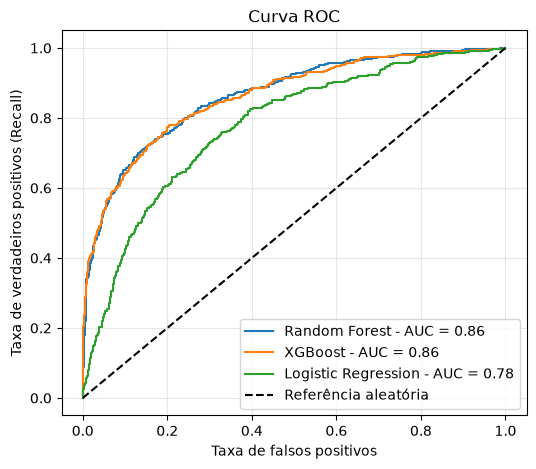

In [580]:
# Curva ROC e pontuação AUC para o modelo Random Forest 
Y_prob_RF = melhor_modelo_RF.predict_proba(X_test)[:, 1]

fpr_RF, tpr_RF, thresholds_RF = roc_curve(Y_test, Y_prob_RF)
roc_auc_RF = roc_auc_score(Y_test, Y_prob_RF)

# Curva ROC e pontuação AUC para o modelo de Regressão Logística
Y_prob_LR = melhor_modelo_LR.predict_proba(X_test)[:, 1]

fpr_LR,  tpr_LR, thresholds_LR = roc_curve(Y_test, Y_prob_LR)
roc_auc_LR = roc_auc_score(Y_test, Y_prob_LR)

# Curva ROC e pontuação AUC para o modelo XGBoost
Y_prob_xgb = melhor_modelo_xgb.predict_proba(X_test)[:, 1]

fpr_XGB,  tpr_XGB, thresholds_XGB = roc_curve(Y_test, Y_prob_xgb)
roc_auc_XGB = roc_auc_score(Y_test, Y_prob_xgb)

# 
fig = plt.figure(figsize=(6, 5))

ax = fig.add_subplot()
ax.plot(fpr_RF, tpr_RF, label=f"Random Forest - AUC = {roc_auc_RF:.2f}")
ax.plot(fpr_XGB, tpr_XGB, label=f"XGBoost - AUC = {roc_auc_XGB:.2f}")
ax.plot(fpr_LR, tpr_LR, label=f"Logistic Regression - AUC = {roc_auc_LR:.2f}")
ax.plot([0, 1], [0, 1], "k--", label="Referência aleatória")

ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos (Recall)")
ax.set_title("Curva ROC")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

A curva ROC (Característica de Operação do Receptor) permite comparar a capacidade de discriminação de diferentes modelos ao representar a relação entre a taxa de verdadeiros positivos (recall) e a taxa de falsos positivos para diferentes limiares de classificação. A AUC, correspondente à área sob essa curva, resume a discriminação global, com valores mais elevados indicando melhor desempenho nesse aspecto. Pela curva ROC, é possível estimar a taxa de falsos positivos associada a um recall desejado para cada modelo.

As curvas ROC dos modelos XGBoost e Random Forest muito próxima e valores de AUC de 0,86 e 0,86 respectivamente, essa proximidade das curvas e dos valores indicam um desempenho semelhante entre os dois modelos, não sendo possível afirmar diretamente que um modelo é melhor que o outro. Já a Regressão logística apresentou um valor de AUC de 0,78 e uma curva ROC mais baixa em todos os pontos, indicando claramente que esse modelo teve um desempenho pior na base analisada.

### Conclusões
A tabela abaixo apresenta as principais características de cada modelo
| Modelo | Acurácia | Recall | Precisão | F1 | AUC | Economia por cliente |
| :----: | :------: | :------------: | :------: | :-: | :-: | :-----: |
| Random Forest | 80,4% | 74,4% | 51,3% | 60,7% | 0,86 | R$ 9,24 |
| Regressão Logística | 71,5% | 70,5% | 38,9% | 50,2% | 0,78 | R$ 6,98 |
| XGBoost | 78,8% | 77,9% | 48,7% | 59,9% | 0,86 | R$ 9,34 |

Esses números mostram um compromisso interessante:
- O Random Forest apresenta maior precisão e menos falsos positivos.
- O XGBoost apresenta maior recall e menos falsos negativos.
- A Regressão Logística apresenta menor recall e precisão, mais falsos positivos e menos verdadeiros positivos 
- O F1 do Random Forest e XGBoost é praticamente igual, já para a Regressão Logística é aproximadamente 10% menor.
- O XGBoost tem uma pequena vantagem numérica no AUC em relação ao Random Forest e a Regressão Logística apresenta o menor valor.
- XGBoost apresentou o melhor desempenho em termos de economia por cliente, seguido de perto pelo Random Forest.


O XGboost apresentou os melhores resultados preliminares, com uma economia por cliente de R$ 9,34, quando comparado com o Random Forest, R$ 9,24, e a Regressão Logística, R$ 6,98. Os resultados de XGBoost e Random Forest foram próximos, para decidir entre os dois modelos seriam necessárias avaliações posteriores antes da implementação em uma linha de produção para o nosso negócio.